<a href="https://colab.research.google.com/github/AsfandyarFarooqi/learning-log/blob/main/week04_least_squares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
measured = np.array([10.02, 9.97, 10.04,10.05])
L_best = measured.mean()
print("best length L =", L_best)
residuals_tape = measured - L_best
print("residuals:", np.round(residuals_tape, 4))
print("sum of squares:", round(np.sum(residuals_tape**2), 5))

best length L = 10.02
residuals: [ 0.   -0.05  0.02  0.03]
sum of squares: 0.0038


In [ ]:
for L in [10.00, 10.01, 10.02]:
    total = np.sum((measured - L)**2)
    print("L =", L, "-> sum of squares:", round(total, 5))

L = 10.0 -> sum of squares: 0.0029
L = 10.01 -> sum of squares: 0.0026
L = 10.02 -> sum of squares: 0.0029


10.01


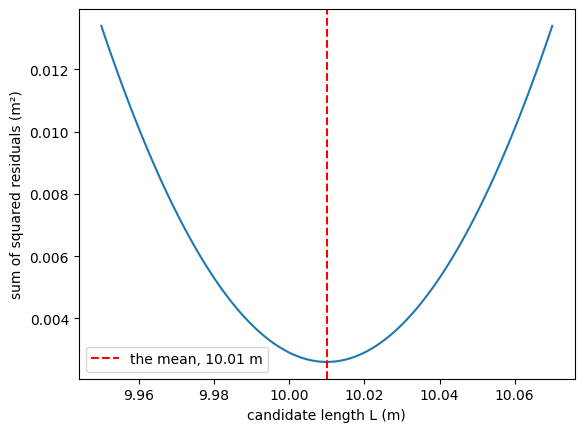

In [ ]:
L_values = np.linspace(9.95, 10.07, 121)
totals = []
for L in L_values:
    totals.append(np.sum((measured - L)**2))
print(np.mean(L_values))
plt.plot(L_values, totals)
plt.axvline(10.01, color="red", linestyle="--", label="the mean, 10.01 m")
plt.xlabel("candidate length L (m)")
plt.ylabel("sum of squared residuals (m²)")
plt.legend()
plt.show()

In [ ]:
import numpy as np

A = np.array([[ 1, 0],
              [-1, 1],
              [ 0, 1]])
b = np.array([2.0, 1.5, 3.5])
pairs = [[0, 1], [0, 2], [1, 2]]
for rows in pairs:
    print("rows =", rows)
    print("A[rows] =")
    print(A[rows])
    print("b[rows] =", b[rows])
    heights = np.linalg.solve(A[rows], b[rows])
    print("-> h_P, h_Q =", np.round(heights, 4))
    print()

rows = [0, 1]
A[rows] =
[[ 1  0]
 [-1  1]]
b[rows] = [2.  1.5]
-> h_P, h_Q = [2.  3.5]

rows = [0, 2]
A[rows] =
[[1 0]
 [0 1]]
b[rows] = [2.  3.5]
-> h_P, h_Q = [2.  3.5]

rows = [1, 2]
A[rows] =
[[-1  1]
 [ 0  1]]
b[rows] = [1.5 3.5]
-> h_P, h_Q = [2.  3.5]



In [ ]:
x_hat, ssr, rank, sv = np.linalg.lstsq(A, b, rcond=None)
print("least-squares h_P, h_Q =", np.round(x_hat, 4))
print("rank of A:", rank)
residuals = b - A @ x_hat
print("residuals:", np.round(residuals, 4))
print("sum of squares:", round(np.sum(residuals**2), 5))
print("lstsq's own sum:", ssr)

least-squares h_P, h_Q = [2.  3.5]
rank of A: 2
residuals: [-0. -0. -0.]
sum of squares: 0.0
lstsq's own sum: [7.88860905e-31]


In [ ]:
for rows in pairs:
    heights = np.linalg.solve(A[rows], b[rows])
    r = b - A @ heights
    print("rows", rows, "-> residuals", np.round(r, 4), "-> sum of squares:", round(np.sum(r**2), 5))
print("least squares -> sum of squares:", round(np.sum(residuals**2), 5))

rows [0, 1] -> residuals [0.  0.  0.1] -> sum of squares: 0.01
rows [0, 2] -> residuals [ 0.  -0.1  0. ] -> sum of squares: 0.01
rows [1, 2] -> residuals [-0.1  0.   0. ] -> sum of squares: 0.01
least squares -> sum of squares: 0.00333


t: [0 1 2 3 4 5 6 7]
east (mm): [  5.  20.  44.  67.  81. 102. 126. 139.]


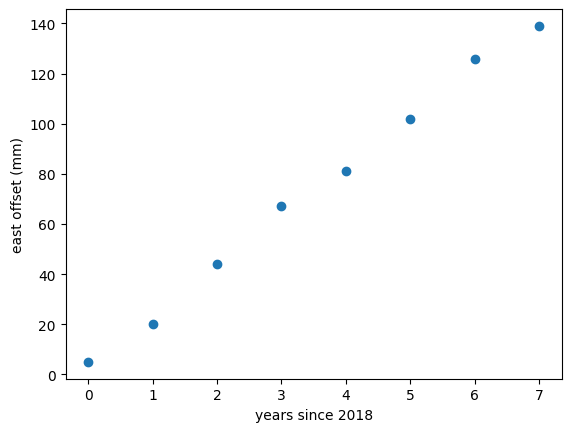

In [ ]:
## Tuesday: fitting a line

t = np.array([0, 1, 2, 3, 4, 5, 6, 7])
east_mm = np.array([5.0, 20.0, 44.0, 67.0, 81.0, 102.0, 126.0, 139.0])
print("t:", t)
print("east (mm):", east_mm)

plt.scatter(t, east_mm)
plt.xlabel("years since 2018")
plt.ylabel("east offset (mm)")
plt.show()

In [ ]:
ones = np.ones(8)
A_line = np.column_stack([t, ones])
print(A_line)
print("A_line has shape", A_line.shape)
x_line, ssr_line, rank_line, sv_line = np.linalg.lstsq(A_line, east_mm, rcond=None)
m, c = x_line
print("slope m =", round(m, 2), "mm per year")
print("intercept c =", round(c, 2), "mm")

[[0. 1.]
 [1. 1.]
 [2. 1.]
 [3. 1.]
 [4. 1.]
 [5. 1.]
 [6. 1.]
 [7. 1.]]
A_line has shape (8, 2)
slope m = 19.71 mm per year
intercept c = 4.0 mm


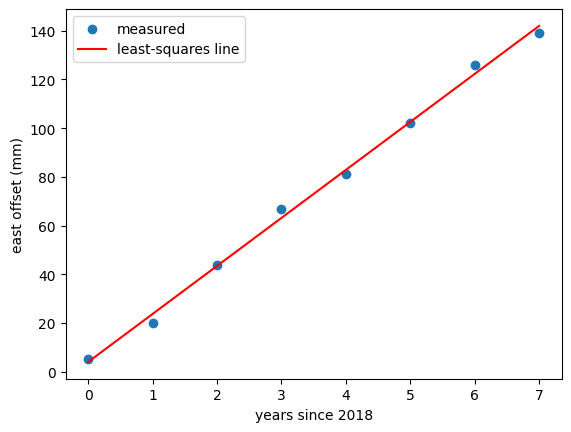

In [ ]:
predicted_line = A_line @ x_line
plt.scatter(t, east_mm, label="measured")
plt.plot(t, predicted_line, color="red", label="least-squares line")
plt.xlabel("years since 2018")
plt.ylabel("east offset (mm)")
plt.legend()
plt.show()

residuals (mm): [ 1.   -3.71  0.57  3.86 -1.86 -0.57  3.71 -3.  ]
sum of squares: 56.57
lstsq's own sum: [56.57]


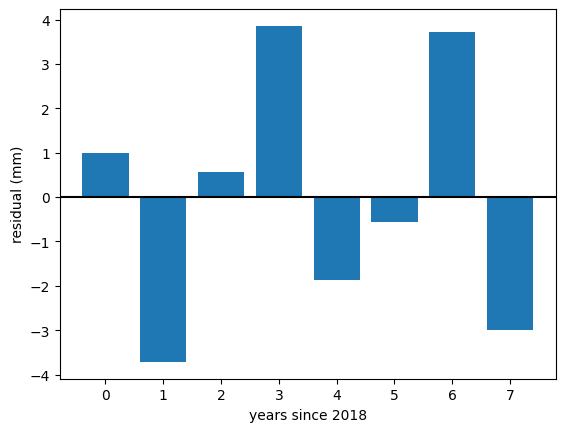

In [ ]:
residuals_line = east_mm - predicted_line
print("residuals (mm):", np.round(residuals_line, 2))
print("sum of squares:", round(np.sum(residuals_line**2), 2))
print("lstsq's own sum:", np.round(ssr_line, 2))
plt.bar(t, residuals_line)
plt.axhline(0, color="black")
plt.xlabel("years since 2018")
plt.ylabel("residual (mm)")
plt.show()

In [ ]:
rmse_line = np.sqrt(np.mean(residuals_line**2))
print("RMSE =", round(rmse_line, 2), "mm")

RMSE = 2.66 mm


In [ ]:
N_line = A_line.T @ A_line
n_line = A_line.T @ east_mm
print("N =")
print(N_line)
print("n =", n_line)

x_normal = np.linalg.solve(N_line, n_line)
print("normal equations:", np.round(x_normal, 2))
print("lstsq:           ", np.round(x_line, 2))
print("same?", np.allclose(x_normal, x_line))
pred_2026 = m * 8 + c
print("predicted east offset in 2026:", round(pred_2026, 1), "mm")

N =
[[140.  28.]
 [ 28.   8.]]
n = [2872.  584.]
normal equations: [19.71  4.  ]
lstsq:            [19.71  4.  ]
same? True
predicted east offset in 2026: 161.7 mm


In [ ]:
east_blunder = east_mm.copy()
east_blunder[3] = 76.0

x_b, ssr_b, rank_b, sv_b = np.linalg.lstsq(A_line, east_blunder, rcond=None)
residuals_b = east_blunder - A_line @ x_b
print("slope with blunder:", round(x_b[0], 2), "mm per year")
print("residuals (mm):", np.round(residuals_b, 2))
print("RMSE:", round(np.sqrt(np.mean(residuals_b**2)), 2), "mm")

slope with blunder: 19.61 mm per year
residuals (mm): [-0.5  -5.11 -0.71 11.68 -2.93 -1.54  2.86 -3.75]
RMSE: 4.95 mm


In [ ]:
b2 = np.array([4.0, 6.0])
for L in [5.0, 6.0]:
    r = b2 - np.array([L, L])
    print("L =", L, "-> residuals", r, "-> sum of squares:", np.sum(r**2), "-> arrow length:", round(np.sqrt(np.sum(r**2)), 3))

L = 5.0 -> residuals [-1.  1.] -> sum of squares: 2.0 -> arrow length: 1.414
L = 6.0 -> residuals [-2.  0.] -> sum of squares: 4.0 -> arrow length: 2.0


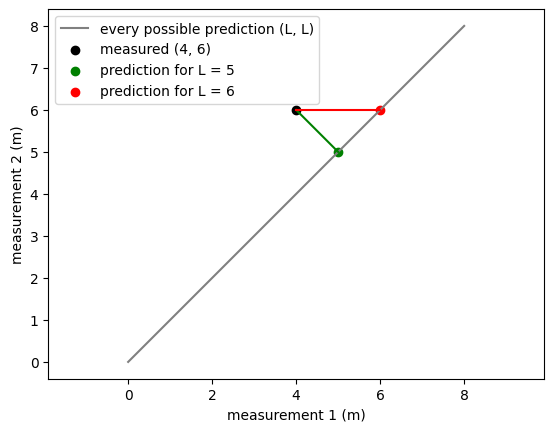

In [ ]:
plt.plot([0, 8], [0, 8], color="gray", label="every possible prediction (L, L)")
plt.scatter(4, 6, color="black", label="measured (4, 6)")
plt.scatter(5, 5, color="green", label="prediction for L = 5")
plt.plot([5, 4], [5, 6], color="green")
plt.scatter(6, 6, color="red", label="prediction for L = 6")
plt.plot([6, 4], [6, 6], color="red")
plt.axis("equal")
plt.xlabel("measurement 1 (m)")
plt.ylabel("measurement 2 (m)")
plt.legend()
plt.show()

In [ ]:
direction = np.array([1.0, 1.0])
r5 = b2 - np.array([5.0, 5.0])
r6 = b2 - np.array([6.0, 6.0])
print("L = 5: residual @ direction =", r5 @ direction)
print("L = 6: residual @ direction =", r6 @ direction)

L = 5: residual @ direction = 0.0
L = 6: residual @ direction = -2.0


In [2]:
## Friday: Helmert as least squares

s_true = 2
theta_true = np.radians(30)
tx_true, ty_true = 3, 1
a_true = s_true * np.cos(theta_true)
b_true = s_true * np.sin(theta_true)
print("a =", round(a_true, 3), " b =", round(b_true, 3))

local = np.array([[0, 0],
                  [1, 0]])
x = local[:, 0]
y = local[:, 1]
X = a_true * x - b_true * y + tx_true
Y = b_true * x + a_true * y + ty_true
print("national X:", np.round(X, 3))
print("national Y:", np.round(Y, 3))

a = 1.732  b = 1.0
national X: [3.    4.732]
national Y: [1. 2.]


In [5]:
x1, y1 = 0, 0
x2, y2 = 1, 0
A_h = np.array([[x1, -y1, 1, 0],
                [y1,  x1, 0, 1],
                [x2, -y2, 1, 0],
                [y2,  x2, 0, 1]])
l_h = np.array([X[0], Y[0], X[1], Y[1]])

print(A_h)
print("observations:", np.round(l_h, 3))

a_hat, b_hat, tx_hat, ty_hat = np.linalg.solve(A_h, l_h)
s_hat = np.sqrt(a_hat**2 + b_hat**2)
theta_hat = np.degrees(np.arctan2(b_hat, a_hat))
print("a, b, tx, ty =", round(a_hat, 3), round(b_hat, 3), round(tx_hat, 3), round(ty_hat, 3))
print("scale s =", round(s_hat, 3))
print("rotation =", round(theta_hat, 2), "degrees")

[[0 0 1 0]
 [0 0 0 1]
 [1 0 1 0]
 [0 1 0 1]]
observations: [3.    1.    4.732 2.   ]
a, b, tx, ty = 1.732 1.0 3.0 1.0
scale s = 2.0
rotation = 30.0 degrees


In [6]:
x_new, y_new = 2, 3
X_new = a_hat * x_new - b_hat * y_new + tx_hat
Y_new = b_hat * x_new + a_hat * y_new + ty_hat
print("national X, Y of the new point:", round(X_new, 3), round(Y_new, 3))

national X, Y of the new point: 3.464 8.196
